In [ ]:
!pip -q install torch torchvision transformers datasets accelerate

In [ ]:
import random, copy, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Subset, random_split
from torchvision import datasets, transforms, models
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:",torch.__version__,"| Device:",device)
if torch.cuda.is_available(): print(torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu | Device: cpu


In [ ]:
scalar=torch.tensor(7)
vector=torch.tensor([1,2,3,4])
matrix=torch.tensor([[1.,2.],[3.,4.]])
tensor3=torch.rand(2,3,4)
print("Scalar:",scalar,"\nVector:",vector,"\nMatrix:\n",matrix)
print("3D shape:",tensor3.shape)
print("Matrix shape:",matrix.shape,"dimensions:",matrix.ndim,"dtype:",matrix.dtype)

Scalar: tensor(7) 
Vector: tensor([1, 2, 3, 4]) 
Matrix:
 tensor([[1., 2.],
        [3., 4.]])
3D shape: torch.Size([2, 3, 4])
Matrix shape: torch.Size([2, 2]) dimensions: 2 dtype: torch.float32


In [ ]:
A=torch.tensor([[1.,2.],[3.,4.]])
B=torch.tensor([[5.,6.],[7.,8.]])
print("Addition:\n",A+B)
print("Subtraction:\n",A-B)
print("Elementwise multiplication:\n",A*B)
print("Matrix multiplication:\n",torch.matmul(A,B))
print("Transpose:\n",A.T)
print("Zeros:\n",torch.zeros(2,3))
print("Ones:\n",torch.ones(2,3))
print("Random:\n",torch.rand(2,3))
print("Range:",torch.arange(0,10))
print("Reshape:\n",torch.arange(1,13).reshape(3,4))

Addition:
 tensor([[ 6.,  8.],
        [10., 12.]])
Subtraction:
 tensor([[-4., -4.],
        [-4., -4.]])
Elementwise multiplication:
 tensor([[ 5., 12.],
        [21., 32.]])
Matrix multiplication:
 tensor([[19., 22.],
        [43., 50.]])
Transpose:
 tensor([[1., 3.],
        [2., 4.]])
Zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
Ones:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
Random:
 tensor([[0.1053, 0.2695, 0.3588],
        [0.1994, 0.5472, 0.0062]])
Range: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
Reshape:
 tensor([[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]])


In [ ]:
x=torch.tensor(2.0,requires_grad=True)
y=x**2+3*x+2
y.backward()
print("y =",y.item())
print("dy/dx =",x.grad.item())  # 7 when x=2

y = 12.0
dy/dx = 7.0


Optimized x: 4.9999284744262695 Final loss: 7.951030056574382e-09


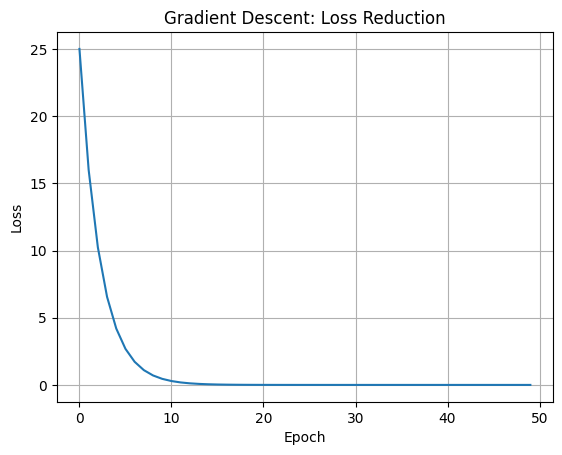

In [ ]:
x=torch.tensor(0.0,requires_grad=True)
lr=0.1
losses=[]
for epoch in range(50):
    loss=(x-5)**2
    losses.append(loss.item())
    loss.backward()
    with torch.no_grad(): x -= lr*x.grad
    x.grad.zero_()
print("Optimized x:",x.item(),"Final loss:",losses[-1])
plt.plot(losses); plt.title("Gradient Descent: Loss Reduction")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(); plt.show()

In [ ]:
X,y=make_moons(n_samples=1200,noise=0.22,random_state=SEED)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=SEED,stratify=y)
scaler=StandardScaler()
Xtr=scaler.fit_transform(Xtr); Xte=scaler.transform(Xte)
def tensor_data(X,y):
    return torch.tensor(X,dtype=torch.float32),torch.tensor(y,dtype=torch.float32).view(-1,1)
Xtr_t,ytr_t=tensor_data(Xtr,ytr); Xte_t,yte_t=tensor_data(Xte,yte)
train_loader=DataLoader(TensorDataset(Xtr_t,ytr_t),batch_size=32,shuffle=True)
test_loader=DataLoader(TensorDataset(Xte_t,yte_t),batch_size=128)

Epoch 5: train acc=0.896, test acc=0.912
Epoch 10: train acc=0.939, test acc=0.958
Epoch 15: train acc=0.945, test acc=0.954
Epoch 20: train acc=0.948, test acc=0.963
Epoch 25: train acc=0.947, test acc=0.963
Epoch 30: train acc=0.947, test acc=0.967


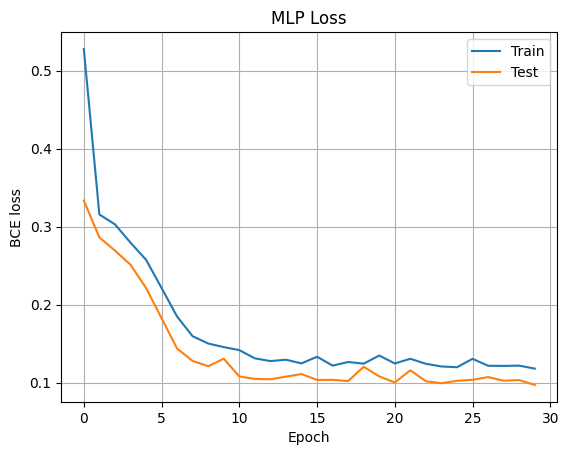

In [ ]:
class BasicMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers=nn.Sequential(nn.Linear(2,16),nn.ReLU(),
                                  nn.Linear(16,8),nn.ReLU(),nn.Linear(8,1))
    def forward(self,x): return self.layers(x)

def binary_epoch(model,loader,loss_fn,optimizer=None):
    training=optimizer is not None
    model.train() if training else model.eval()
    total_loss=correct=total=0
    with torch.set_grad_enabled(training):
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device)
            logits=model(xb); loss=loss_fn(logits,yb)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item()*len(xb)
            correct += ((torch.sigmoid(logits)>=.5)==yb).sum().item()
            total += len(xb)
    return total_loss/total,correct/total

mlp=BasicMLP().to(device)
bce=nn.BCEWithLogitsLoss()
opt=optim.Adam(mlp.parameters(),lr=.01)
mlp_train,mlp_test=[],[]
for epoch in range(30):
    tl,ta=binary_epoch(mlp,train_loader,bce,opt)
    vl,va=binary_epoch(mlp,test_loader,bce)
    mlp_train.append(tl); mlp_test.append(vl)
    if (epoch+1)%5==0: print(f"Epoch {epoch+1}: train acc={ta:.3f}, test acc={va:.3f}")
plt.plot(mlp_train,label="Train"); plt.plot(mlp_test,label="Test")
plt.title("MLP Loss"); plt.xlabel("Epoch"); plt.ylabel("BCE loss"); plt.legend(); plt.grid(); plt.show()

100%|██████████| 26.4M/26.4M [00:02<00:00, 8.84MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 136kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.8MB/s]


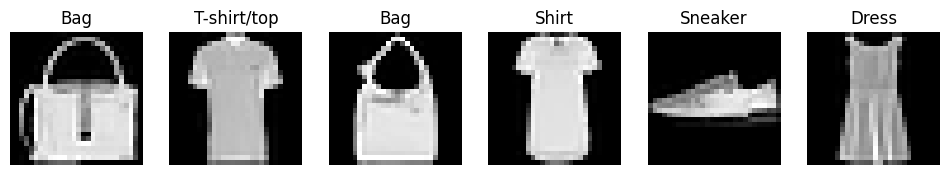

In [ ]:
fashion_tf=transforms.ToTensor()
fashion_train_full=datasets.FashionMNIST("./data",train=True,download=True,transform=fashion_tf)
fashion_test_full=datasets.FashionMNIST("./data",train=False,download=True,transform=fashion_tf)
fashion_train=Subset(fashion_train_full,range(10000))
fashion_test=Subset(fashion_test_full,range(2000))
ftrain=DataLoader(fashion_train,batch_size=64,shuffle=True)
ftest=DataLoader(fashion_test,batch_size=128)
class_names=fashion_train_full.classes
imgs,labs=next(iter(ftrain))
fig,ax=plt.subplots(1,6,figsize=(12,2.5))
for a,im,lab in zip(ax,imgs[:6],labs[:6]):
    a.imshow(im.squeeze(),cmap="gray"); a.set_title(class_names[lab]); a.axis("off")
plt.show()

Epoch 1/3: train acc=0.774, test acc=0.865
Epoch 2/3: train acc=0.859, test acc=0.880
Epoch 3/3: train acc=0.878, test acc=0.887


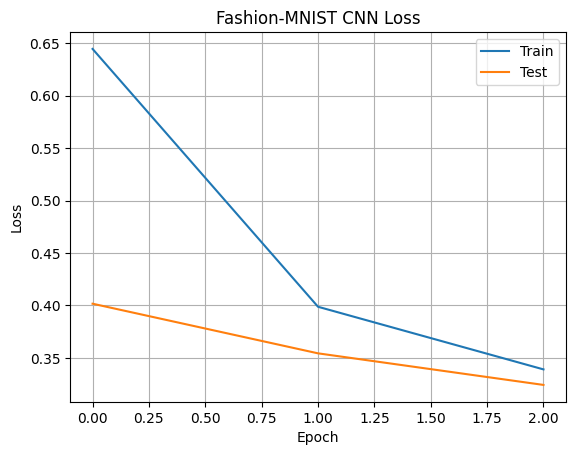

In [ ]:
class FashionCNN(nn.Module):
    def __init__(self,dropout=.25):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(1,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(64*7*7,128),
                                      nn.ReLU(),nn.Dropout(dropout),nn.Linear(128,10))
    def forward(self,x): return self.classifier(self.features(x))

def class_epoch(model,loader,loss_fn,optimizer=None):
    training=optimizer is not None
    model.train() if training else model.eval()
    total_loss=correct=total=0
    with torch.set_grad_enabled(training):
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device)
            logits=model(xb); loss=loss_fn(logits,yb)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss+=loss.item()*len(xb)
            correct+=(logits.argmax(1)==yb).sum().item(); total+=len(xb)
    return total_loss/total,correct/total

cnn=FashionCNN().to(device)
cnn_loss=nn.CrossEntropyLoss()
cnn_opt=optim.Adam(cnn.parameters(),lr=.001)
cnn_tr,cnn_te=[],[]
for epoch in range(3):
    tl,ta=class_epoch(cnn,ftrain,cnn_loss,cnn_opt)
    vl,va=class_epoch(cnn,ftest,cnn_loss)
    cnn_tr.append(tl); cnn_te.append(vl)
    print(f"Epoch {epoch+1}/3: train acc={ta:.3f}, test acc={va:.3f}")
plt.plot(cnn_tr,label="Train"); plt.plot(cnn_te,label="Test")
plt.title("Fashion-MNIST CNN Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(); plt.show()

In [ ]:
cnn.eval(); preds=[]; actual=[]
with torch.no_grad():
    for xb,yb in ftest:
        preds.extend(cnn(xb.to(device)).argmax(1).cpu().numpy())
        actual.extend(yb.numpy())
print("CNN test accuracy:",accuracy_score(actual,preds))
print(classification_report(actual,preds,target_names=class_names))

CNN test accuracy: 0.8875
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.83      0.84       200
     Trouser       1.00      0.98      0.99       203
    Pullover       0.81      0.88      0.84       214
       Dress       0.90      0.84      0.87       190
        Coat       0.85      0.79      0.82       219
      Sandal       0.97      0.96      0.97       195
       Shirt       0.68      0.75      0.71       197
     Sneaker       0.94      0.95      0.95       200
         Bag       0.98      0.96      0.97       194
  Ankle boot       0.95      0.95      0.95       188

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000



In [ ]:
rng=np.random.default_rng(SEED)
Xseq=rng.normal(size=(3000,20,1)).astype("float32")
yseq=(Xseq.mean(axis=1).squeeze()>0).astype("int64")
Xs_tr,Xs_te,ys_tr,ys_te=train_test_split(Xseq,yseq,test_size=.2,random_state=SEED,stratify=yseq)
seq_train=DataLoader(TensorDataset(torch.tensor(Xs_tr),torch.tensor(ys_tr)),batch_size=64,shuffle=True)
seq_test=DataLoader(TensorDataset(torch.tensor(Xs_te),torch.tensor(ys_te)),batch_size=128)

RNN test accuracy: 0.9467
LSTM test accuracy: 0.955
GRU test accuracy: 0.9683


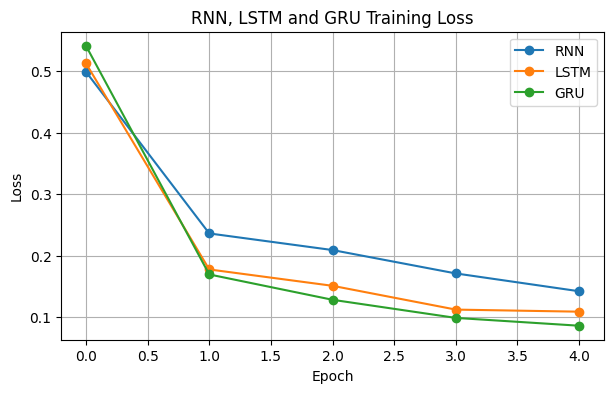

,Model,Test Accuracy
0,RNN,0.946667
1,LSTM,0.955000
2,GRU,0.968333


In [ ]:
class SequenceClassifier(nn.Module):
    def __init__(self,kind="RNN",hidden=32):
        super().__init__()
        layer={"RNN":nn.RNN,"LSTM":nn.LSTM,"GRU":nn.GRU}[kind]
        self.rnn=layer(input_size=1,hidden_size=hidden,batch_first=True)
        self.drop=nn.Dropout(.2); self.fc=nn.Linear(hidden,2)
    def forward(self,x):
        output,state=self.rnn(x)
        h=state[0] if isinstance(state,tuple) else state
        return self.fc(self.drop(h[-1]))

def train_sequence(kind,epochs=5):
    net=SequenceClassifier(kind).to(device)
    loss_fn=nn.CrossEntropyLoss(); optimizer=optim.Adam(net.parameters(),lr=.003)
    history=[]
    for ep in range(epochs):
        net.train(); running=correct=total=0
        for xb,yb in seq_train:
            xb,yb=xb.to(device),yb.to(device)
            optimizer.zero_grad(); logits=net(xb); loss=loss_fn(logits,yb)
            loss.backward(); optimizer.step()
            running+=loss.item()*len(xb); correct+=(logits.argmax(1)==yb).sum().item(); total+=len(xb)
        history.append(running/total)
    net.eval(); p=[]; a=[]
    with torch.no_grad():
        for xb,yb in seq_test:
            p.extend(net(xb.to(device)).argmax(1).cpu().numpy()); a.extend(yb.numpy())
    return net,accuracy_score(a,p),history

seq_results={}
for kind in ["RNN","LSTM","GRU"]:
    net,acc,hist=train_sequence(kind)
    seq_results[kind]={"model":net,"accuracy":acc,"loss":hist}
    print(kind,"test accuracy:",round(acc,4))
plt.figure(figsize=(7,4))
for kind,result in seq_results.items(): plt.plot(result["loss"],marker="o",label=kind)
plt.title("RNN, LSTM and GRU Training Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(); plt.show()
pd.DataFrame({"Model":list(seq_results),"Test Accuracy":[v["accuracy"] for v in seq_results.values()]})

Epoch 1: train loss=0.7736, val loss=0.4839, val acc=0.824
Epoch 2: train loss=0.4865, val loss=0.4358, val acc=0.841
Epoch 3: train loss=0.4169, val loss=0.4101, val acc=0.854
Epoch 4: train loss=0.3651, val loss=0.3810, val acc=0.863
Epoch 5: train loss=0.3130, val loss=0.3702, val acc=0.875
Epoch 6: train loss=0.2952, val loss=0.3516, val acc=0.890
Epoch 7: train loss=0.2690, val loss=0.3375, val acc=0.888
Epoch 8: train loss=0.2482, val loss=0.3426, val acc=0.887
Epoch 9: train loss=0.2365, val loss=0.3924, val acc=0.882
Early stopping triggered


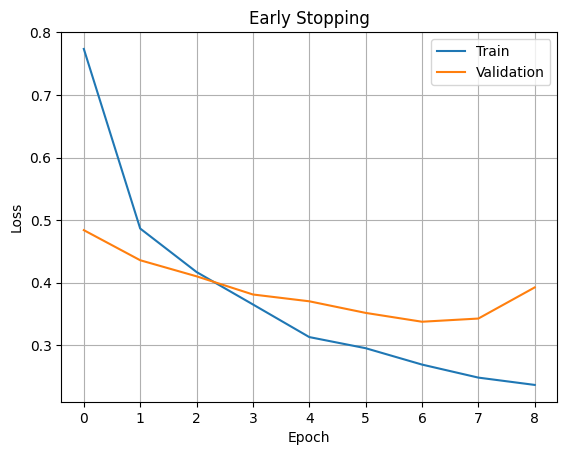

In [ ]:
reg_train_full=Subset(fashion_train_full,range(8000))
tr_part,val_part=random_split(reg_train_full,[7000,1000],generator=torch.Generator().manual_seed(SEED))
reg_train=DataLoader(tr_part,batch_size=64,shuffle=True)
reg_val=DataLoader(val_part,batch_size=128)
reg_model=FashionCNN(dropout=.4).to(device)
reg_opt=optim.Adam(reg_model.parameters(),lr=.001)
best_loss=float("inf"); best_state=copy.deepcopy(reg_model.state_dict())
patience,wait=2,0
tr_hist=[]; val_hist=[]
for epoch in range(10):
    tl,ta=class_epoch(reg_model,reg_train,cnn_loss,reg_opt)
    vl,va=class_epoch(reg_model,reg_val,cnn_loss)
    tr_hist.append(tl); val_hist.append(vl)
    print(f"Epoch {epoch+1}: train loss={tl:.4f}, val loss={vl:.4f}, val acc={va:.3f}")
    if vl<best_loss:
        best_loss=vl; best_state=copy.deepcopy(reg_model.state_dict()); wait=0
    else:
        wait+=1
        if wait>=patience:
            print("Early stopping triggered"); break
reg_model.load_state_dict(best_state)
plt.plot(tr_hist,label="Train"); plt.plot(val_hist,label="Validation")
plt.title("Early Stopping"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(); plt.show()

In [ ]:
imagenet_mean=(.485,.456,.406); imagenet_std=(.229,.224,.225)
cifar_tf=transforms.Compose([
    transforms.Resize((224,224)),transforms.ToTensor(),
    transforms.Normalize(imagenet_mean,imagenet_std)])
cifar_train_full=datasets.CIFAR10("./data",train=True,download=True,transform=cifar_tf)
cifar_test_full=datasets.CIFAR10("./data",train=False,download=True,transform=cifar_tf)
cifar_train=DataLoader(Subset(cifar_train_full,range(2000)),batch_size=32,shuffle=True)
cifar_test=DataLoader(Subset(cifar_test_full,range(500)),batch_size=64)

100%|██████████| 170M/170M [40:24<00:00, 70.3kB/s]


In [ ]:
weights=models.ResNet18_Weights.DEFAULT
resnet=models.resnet18(weights=weights)
for param in resnet.parameters(): param.requires_grad=False
resnet.fc=nn.Linear(resnet.fc.in_features,10)
resnet=resnet.to(device)
resnet_opt=optim.Adam(resnet.fc.parameters(),lr=.001)
for epoch in range(2):
    tl,ta=class_epoch(resnet,cifar_train,cnn_loss,resnet_opt)
    vl,va=class_epoch(resnet,cifar_test,cnn_loss)
    print(f"Epoch {epoch+1}/2: train acc={ta:.3f}, test acc={va:.3f}")
print("CIFAR-10 classes:",cifar_train_full.classes)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 239MB/s]


Epoch 1/2: train acc=0.409, test acc=0.594
Epoch 2/2: train acc=0.680, test acc=0.652
CIFAR-10 classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
from transformers import pipeline
sentiment=pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1
)
texts=[
    "The project was interesting and I learned a lot.",
    "The application is confusing and does not work well.",
    "The presentation was clear and informative."
]
for text,result in zip(texts,sentiment(texts)):
    print(text,"\n",result,"\n")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

The project was interesting and I learned a lot. 
 {'label': 'POSITIVE', 'score': 0.997602641582489} 

The application is confusing and does not work well. 
 {'label': 'NEGATIVE', 'score': 0.9997959733009338} 

The presentation was clear and informative. 
 {'label': 'POSITIVE', 'score': 0.9998656511306763} 



In [ ]:
from transformers import pipeline
generator=pipeline(
    "text-generation",model="sshleifer/tiny-gpt2",
    device=0 if torch.cuda.is_available() else -1
)
prompt="Artificial intelligence is changing education because"
generated=generator(prompt,max_new_tokens=50,num_return_sequences=1,
                    do_sample=True,temperature=.8,pad_token_id=50256)
print(generated[0]["generated_text"])

In [ ]:
summary=pd.DataFrame([
 ["PyTorch fundamentals","Tensors, operations, autograd","Gradient calculation"],
 ["Basic neural network","MLP, loss, optimizer, training loop","Binary classification"],
 ["CNN","Convolution, pooling, batch norm, dropout","Fashion-MNIST"],
 ["RNN/LSTM/GRU","Recurrent sequence processing","Synthetic sequence classification"],
 ["Regularization","Dropout, batch normalization, early stopping","Generalization"],
 ["Transfer learning","Pretrained ResNet18","CIFAR-10"],
 ["Transformers","DistilBERT","Sentiment analysis"],
 ["LLM","Tiny GPT-2","Text generation"]
],columns=["Area","Concepts","Practical"])
summary